In [9]:
import pandas as pd 
import matplotlib.pyplot as plt

analysisData = pd.read_csv("../data/analysisData.csv")
analysisData.shape

(3895, 25)

In [3]:
analysisData[["qualiPosition", "position"]].describe()

,qualiPosition,position
count,3895.000000,3895.000000
mean,10.356098,9.168935
std,5.900021,5.121604
min,1.000000,1.000000
25%,5.000000,5.000000
50%,10.000000,9.000000
75%,15.000000,13.000000
max,22.000000,22.000000


In [4]:
analysisData["positionDiff"].describe()

count    3895.000000
mean        1.187163
std         3.856656
min       -18.000000
25%        -1.000000
50%         1.000000
75%         3.000000
max        18.000000
Name: positionDiff, dtype: float64

In [5]:
analysisData[["qualiPosition", "position"]].corr()

,qualiPosition,position
qualiPosition,1.000000,0.763914
position,0.763914,1.000000


In [6]:
spearmanCorr = analysisData[["qualiPosition", "position"]].corr(method="spearman")
spearmanCorr

,qualiPosition,position
qualiPosition,1.000000,0.771365
position,0.771365,1.000000


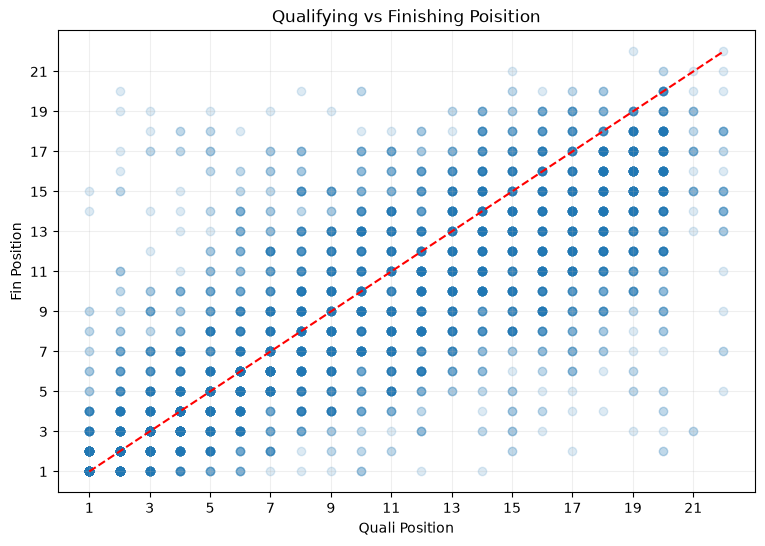

In [20]:
plt.figure(figsize=(9,6))
plt.scatter(analysisData["qualiPosition"], analysisData["position"], alpha=0.15)
plt.plot([1,22], [1,22], linestyle="--", color="red")
plt.xlabel("Quali Position")
plt.ylabel("Fin Position")
plt.title("Qualifying vs Finishing Poisition")
plt.xticks(range(1,23,2))
plt.yticks(range(1,23,2))
plt.grid(alpha=0.2)
plt.show()

In [21]:
circuitCounts = (analysisData.groupby("circuitName").size().sort_values(ascending=False))
circuitCounts

circuitName
Red Bull Ring                           227
Bahrain International Circuit           207
Silverstone Circuit                     199
Circuit de Barcelona-Catalunya          199
Hungaroring                             194
Yas Marina Circuit                      193
Circuit de Spa-Francorchamps            191
Autodromo Nazionale di Monza            190
Autódromo José Carlos Pace              168
Circuit de Monaco                       165
Suzuka Circuit                          161
Circuit of the Americas                 161
Autódromo Hermanos Rodríguez            155
Circuit Gilles Villeneuve               150
Marina Bay Street Circuit               147
Sochi Autodrom                          138
Albert Park Grand Prix Circuit          136
Baku City Circuit                       130
Shanghai International Circuit          127
Circuit Paul Ricard                      73
Circuit Park Zandvoort                   73
Autodromo Enzo e Dino Ferrari            69
Hockenheimring      

In [19]:
def calculateSpearman(group):
    spearmanCorr = group["qualiPosition"].corr(group["position"],method="spearman")
    return spearmanCorr

circuitCorr = (analysisData.groupby("circuitName").apply(calculateSpearman, include_groups=False).sort_values(ascending=False))
circuitCorr

circuitName
Autodromo Internazionale del Mugello    0.916084
Autódromo Internacional do Algarve      0.857409
Circuit de Monaco                       0.856446
Circuit de Barcelona-Catalunya          0.841237
Suzuka Circuit                          0.840328
Circuit Paul Ricard                     0.838397
Autodromo Nazionale di Monza            0.821597
Autódromo Hermanos Rodríguez            0.820693
Yas Marina Circuit                      0.811564
Shanghai International Circuit          0.811282
Jeddah Corniche Circuit                 0.797471
Circuit de Spa-Francorchamps            0.794530
Circuit of the Americas                 0.790599
Albert Park Grand Prix Circuit          0.789489
Circuit Park Zandvoort                  0.770165
Circuit Gilles Villeneuve               0.769961
Miami International Autodrome           0.769887
Losail International Circuit            0.761990
Silverstone Circuit                     0.760569
Red Bull Ring                           0.755277
Marina B

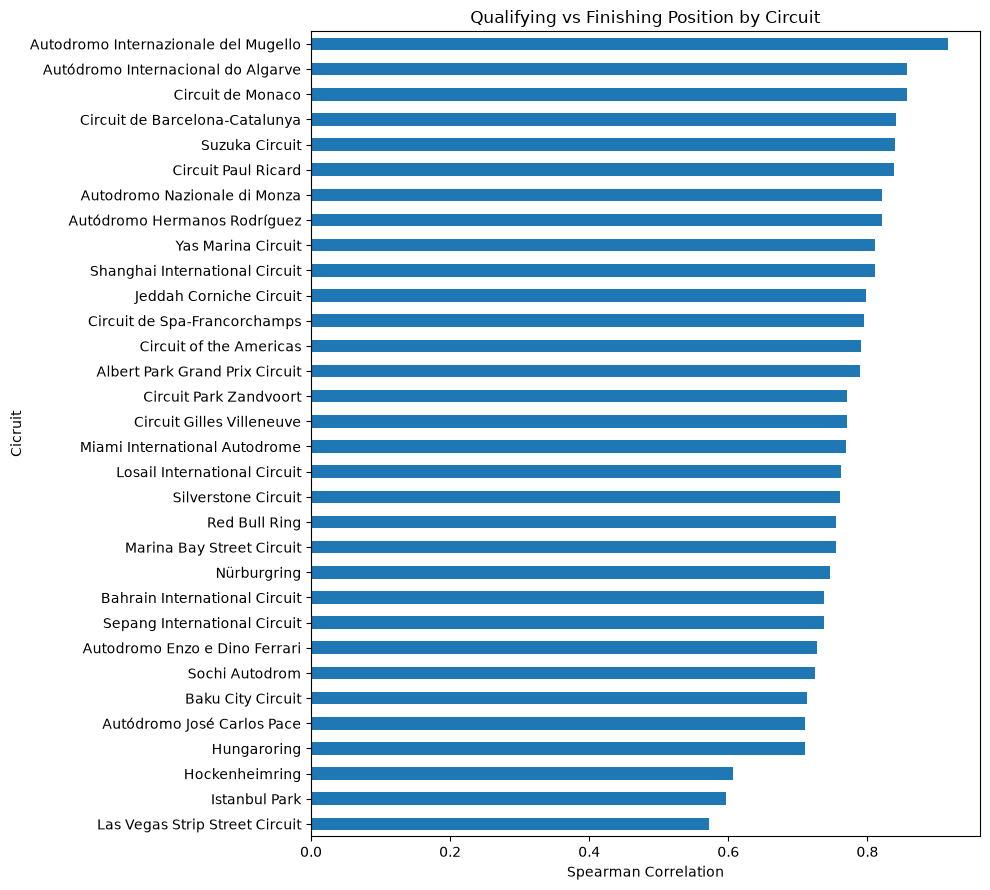

In [22]:
plt.figure(figsize=(10,9))
circuitCorr.sort_values().plot(kind="barh")
plt.xlabel("Spearman Correlation")
plt.ylabel("Cicruit")
plt.title("Qualifying vs Finishing Position by Circuit")
plt.tight_layout()
plt.show()

In [23]:
noRacesPerCircuit = (analysisData.groupby("circuitName")["raceId"].nunique().sort_values(ascending=False))
noRacesPerCircuit

circuitName
Red Bull Ring                           13
Silverstone Circuit                     12
Bahrain International Circuit           12
Yas Marina Circuit                      11
Autodromo Nazionale di Monza            11
Hungaroring                             11
Circuit de Spa-Francorchamps            11
Circuit de Barcelona-Catalunya          11
Circuit de Monaco                       10
Autódromo José Carlos Pace              10
Circuit of the Americas                 10
Suzuka Circuit                           9
Marina Bay Street Circuit                9
Albert Park Grand Prix Circuit           9
Circuit Gilles Villeneuve                9
Autódromo Hermanos Rodríguez             9
Baku City Circuit                        8
Sochi Autodrom                           8
Shanghai International Circuit           7
Circuit Paul Ricard                      4
Sepang International Circuit             4
Circuit Park Zandvoort                   4
Hockenheimring                           4

In [28]:
for threshold in [3,5,7]:
    validCircuits = noRacesPerCircuit[noRacesPerCircuit >= threshold].index
    filteredCorr = circuitCorr.loc[validCircuits]
    print(f"\nmin {threshold} races: ",
          f"included circuits: {len(filteredCorr)}",
          f"range: {filteredCorr.min():.3f} to {filteredCorr.max():.3f}")


min 3 races:  included circuits: 27 range: 0.606 to 0.856

min 5 races:  included circuits: 19 range: 0.710 to 0.856

min 7 races:  included circuits: 19 range: 0.710 to 0.856


In [29]:
excludedCircuits = noRacesPerCircuit[(noRacesPerCircuit >= 3) & (noRacesPerCircuit < 5)].index
print(circuitCorr.loc[excludedCircuits].sort_values())


circuitName
Hockenheimring                   0.606324
Autodromo Enzo e Dino Ferrari    0.726802
Sepang International Circuit     0.737913
Losail International Circuit     0.761990
Miami International Autodrome    0.769887
Circuit Park Zandvoort           0.770165
Jeddah Corniche Circuit          0.797471
Circuit Paul Ricard              0.838397
dtype: float64


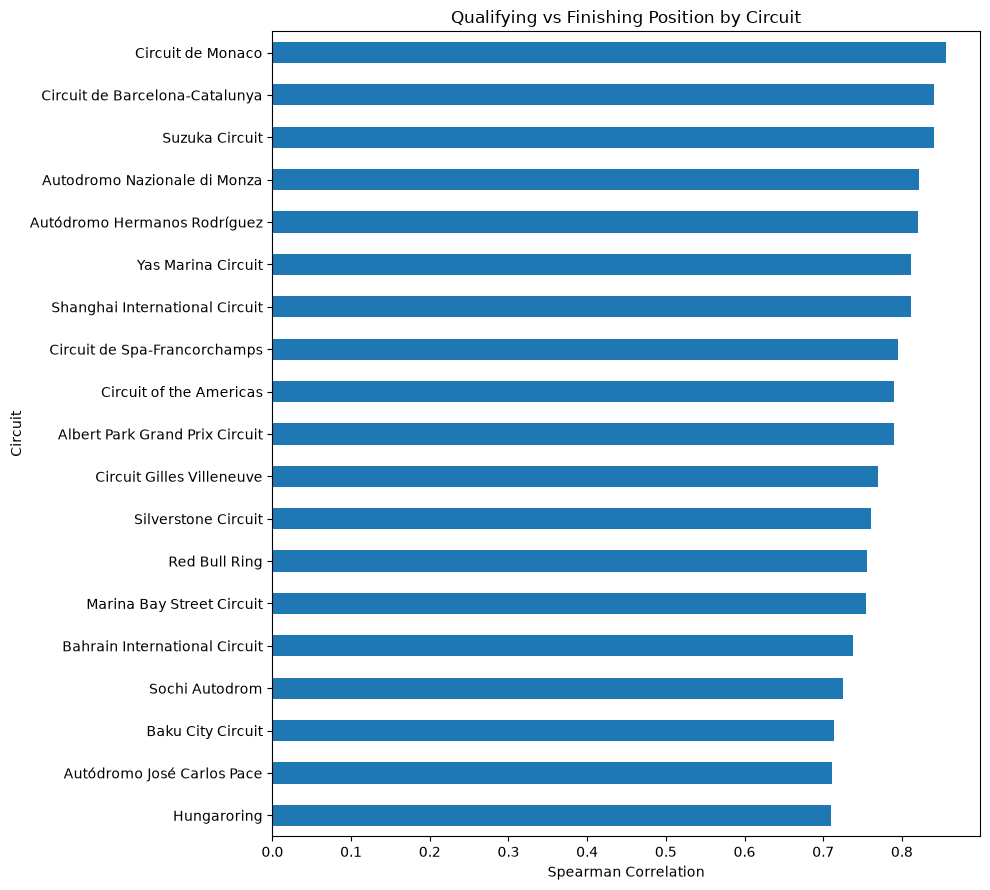

In [40]:
validCircuits = noRacesPerCircuit[noRacesPerCircuit >= 5].index
validCircuitCorr = circuitCorr.loc[validCircuits].sort_values()


plt.figure(figsize=(10,9))
validCircuitCorr.sort_values().plot(kind="barh")
plt.xlabel("Spearman Correlation")
plt.ylabel("Circuit")
plt.title("Qualifying vs Finishing Position by Circuit")
plt.tight_layout()
plt.show()

In [33]:
analysisData["absPositionDiff"] = analysisData["positionDiff"].abs()

circuitAbsDiff = (analysisData.groupby("circuitName")["absPositionDiff"].mean().loc[validCircuits].sort_values())

circuitAbsDiff

circuitName
Yas Marina Circuit                2.404145
Circuit de Barcelona-Catalunya    2.457286
Suzuka Circuit                    2.472050
Circuit de Monaco                 2.472727
Autódromo Hermanos Rodríguez      2.612903
Shanghai International Circuit    2.629921
Autodromo Nazionale di Monza      2.642105
Circuit de Spa-Francorchamps      2.790576
Circuit Gilles Villeneuve         2.953333
Silverstone Circuit               2.959799
Albert Park Grand Prix Circuit    2.977941
Circuit of the Americas           3.000000
Sochi Autodrom                    3.043478
Red Bull Ring                     3.096916
Autódromo José Carlos Pace        3.172619
Bahrain International Circuit     3.202899
Marina Bay Street Circuit         3.285714
Hungaroring                       3.324742
Baku City Circuit                 3.523077
Name: absPositionDiff, dtype: float64

In [39]:
absCorrComparison = pd.DataFrame({"correlation": circuitCorr, "absoluteDifference": circuitAbsDiff}).dropna().sort_values(by=["correlation"])
absCorrComparison

,correlation,absoluteDifference
circuitName,,
Hungaroring,0.709649,3.324742
Autódromo José Carlos Pace,0.710760,3.172619
Baku City Circuit,0.713114,3.523077
Sochi Autodrom,0.725130,3.043478
Bahrain International Circuit,0.738252,3.202899
Marina Bay Street Circuit,0.754494,3.285714
Red Bull Ring,0.755277,3.096916
Silverstone Circuit,0.760569,2.959799
Circuit Gilles Villeneuve,0.769961,2.953333


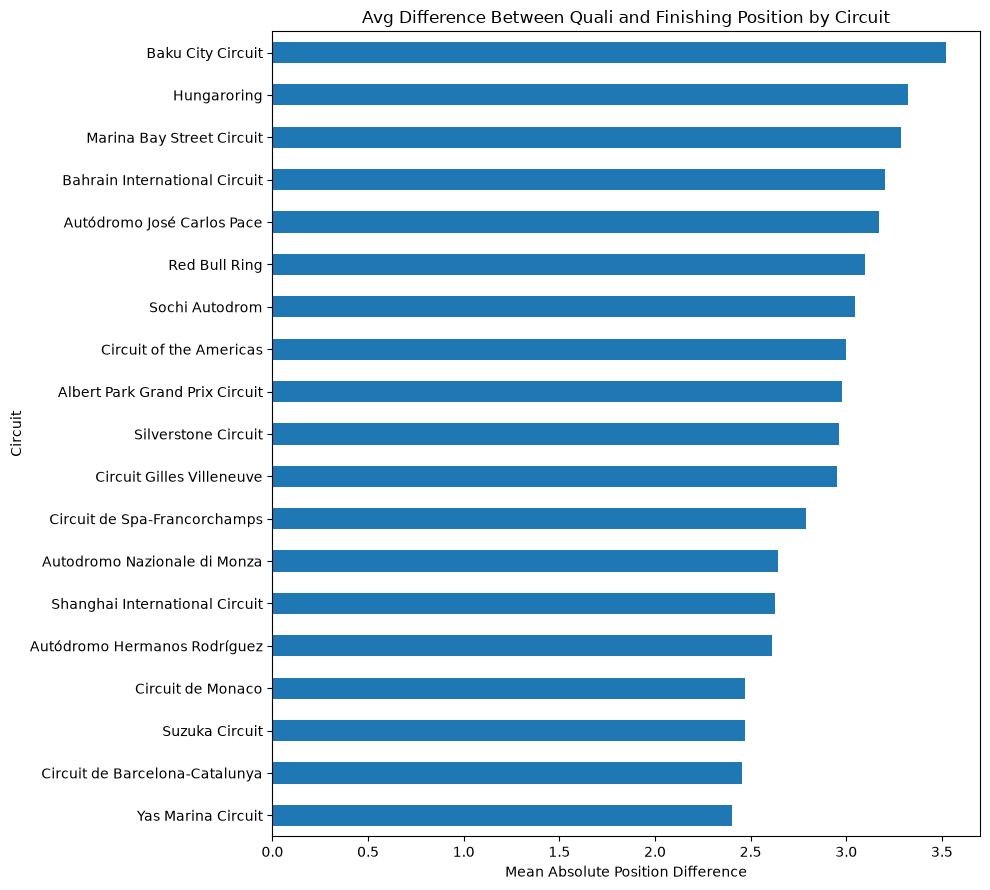

In [41]:
plt.figure(figsize=(10,9))
circuitAbsDiff.sort_values().plot(kind="barh")
plt.xlabel("Mean Absolute Position Difference")
plt.ylabel("Circuit")
plt.title("Avg Difference Between Quali and Finishing Position by Circuit")
plt.tight_layout()
plt.show()